In [126]:
from scipy.ndimage import maximum_filter1d
import numpy as np
from numpy import linspace, exp, sin, log, log10, pi
import matplotlib.pyplot as plt
plt.rc('font', size=14) # controls default text sizes

### We first find the dispersion relation. The quasinormal mode must be of the form $\sin(kx)$ for $x<a$ and $\sin(ka)\exp(ikx)/\exp(ika)$ for $x>a$. In addition, we must have $i\sin(ka)-\cos(ka)=-Mk\sin(ka)\rightarrow \exp(-ika)=Mk\sin(ka)\rightarrow 1-(M/a)(ka)\exp(ika)\sin(ka)=0$

### For large values of $M/a$, there is clearly a root near $ka=0$. To lowest order in $(M/a)$, this root may be found by expanding the dispersion relation to give $1-(M/a)(ka)^2\approx 0\rightarrow (ka)\approx \pm\sqrt{M/a}$. At one higher order, the dispersion relation becomes $1-(M/a)(ka)^2-i(M/a)(ka)^3$. If we set $(ka)\approx \pm \sqrt{(M/a)}+\Delta$, we obtain, to first order in $\Delta$, $\mp 2\Delta-i\Big(\pm(M/a)+ 3\Delta \sqrt{M/a}\Big)=0 \rightarrow \Delta = -(i/2)(M/a)$

In [2]:
def dispersion_relation(m_over_a, ka): # Implements the exact dispersion relation from the cell above 
    return 1-m_over_a*ka*exp(1j*ka)*sin(ka)

In [60]:
num_real = 5000
num_imag = 5000
real_ka = linspace(0.618, 0.6185, num_real)
imag_ka = linspace(-0.213, -0.2125, num_imag)
ka = real_ka.reshape((num_real, 1)).repeat(num_imag, axis=1)+1j*imag_ka.reshape((1, num_imag)).repeat(num_real, axis=0);
m_over_a = 2
mode_condition = dispersion_relation(m_over_a, ka);
mode_heatmap_data = log(np.abs(mode_condition))
first_mode_idx = mode_heatmap_data.argmin();
first_ka_j = ka.flatten()[first_mode_idx]

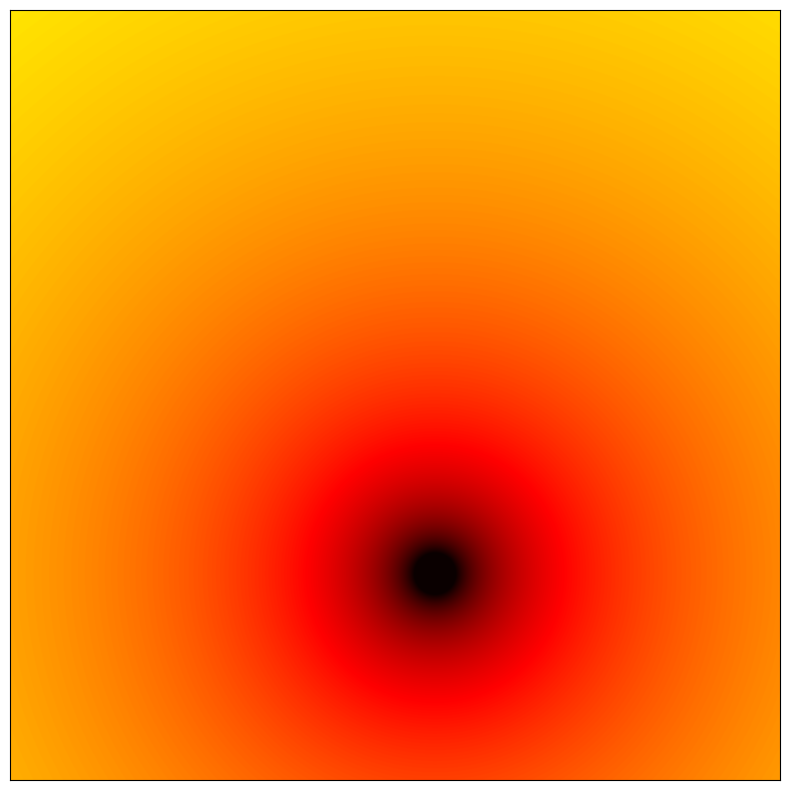

In [61]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(mode_heatmap_data.T, cmap="hot", origin="lower", vmax=-5, vmin=-10);
ax.set_xticks([]);
ax.set_yticks([]);

In [69]:
ka_j_v = []
ka_j_v.append(first_ka_j)
for j in range(1, 11):
    print(f"j={j}");
    real_ka = linspace(j*pi-2e-1, j*pi+2e-1, num_real)
    imag_ka = linspace(-0.03, 0, num_imag)
    ka = real_ka.reshape((num_real, 1)).repeat(num_imag, axis=1)+1j*imag_ka.reshape((1, num_imag)).repeat(num_real, axis=0);
    mode_condition = dispersion_relation(m_over_a, ka);
    mode_heatmap_data = log(np.abs(mode_condition))
    mode_idx = mode_heatmap_data.argmin();
    ka_j = ka.flatten()[mode_idx]
    ka_j_v.append(ka_j)

j=1
j=2
j=3
j=4
j=5
j=6
j=7
j=8
j=9
j=10


In [10]:
def norm(m_over_a, ka_j): # Norm of the resonance state
    a_over_m = 1/m_over_a
    return (ka_j/2)*(1+a_over_m/ka_j/(ka_j+2j*a_over_m))

def completeness(m_over_a, ka_j, delta_over_a, x_over_a, y_over_a): # One term for the completeness relation for the resonance state
    return sin(ka_j*x_over_a)*sin(ka_j*y_over_a)*sin(ka_j*delta_over_a)/norm(m_over_a, ka_j)

### We now check the completeness relation. First, note that $\int_{y-\Delta}^{y+\Delta} \sin(ky')\text{d}y'=\frac{1}{k}\Big(\cos(k(y'-\Delta))-\cos(k(y'+\Delta)) \Big)=\frac{2}{k}\sin(ky)\sin(k\Delta)$

In [98]:
m_over_a = 2
y_over_a = 0.25
x_over_a = 0.30
delta_over_a = 0.1
completeness_condition = 0 
completeness_condition_v = []
num_qnms_v = []
num_qnms = 0
for ka_j in ka_j_v:
    completeness_condition += completeness(m_over_a, ka_j, delta_over_a, x_over_a, y_over_a)
    completeness_condition += completeness(m_over_a, -np.conj(ka_j), delta_over_a, x_over_a, y_over_a)
    completeness_condition_v.append(completeness_condition)
    num_qnms += 2
    num_qnms_v.append(num_qnms)
for m in range(11, 1000000):
    ka_j = m*pi
    completeness_condition += completeness(m_over_a, ka_j, delta_over_a, x_over_a, y_over_a)
    completeness_condition += completeness(m_over_a, -np.conj(ka_j), delta_over_a, x_over_a, y_over_a)
    completeness_condition_v.append(completeness_condition)
    num_qnms += 2
    num_qnms_v.append(num_qnms)

In [121]:
envelope = maximum_filter1d(np.abs(np.real(completeness_condition_v)-1), size=50)

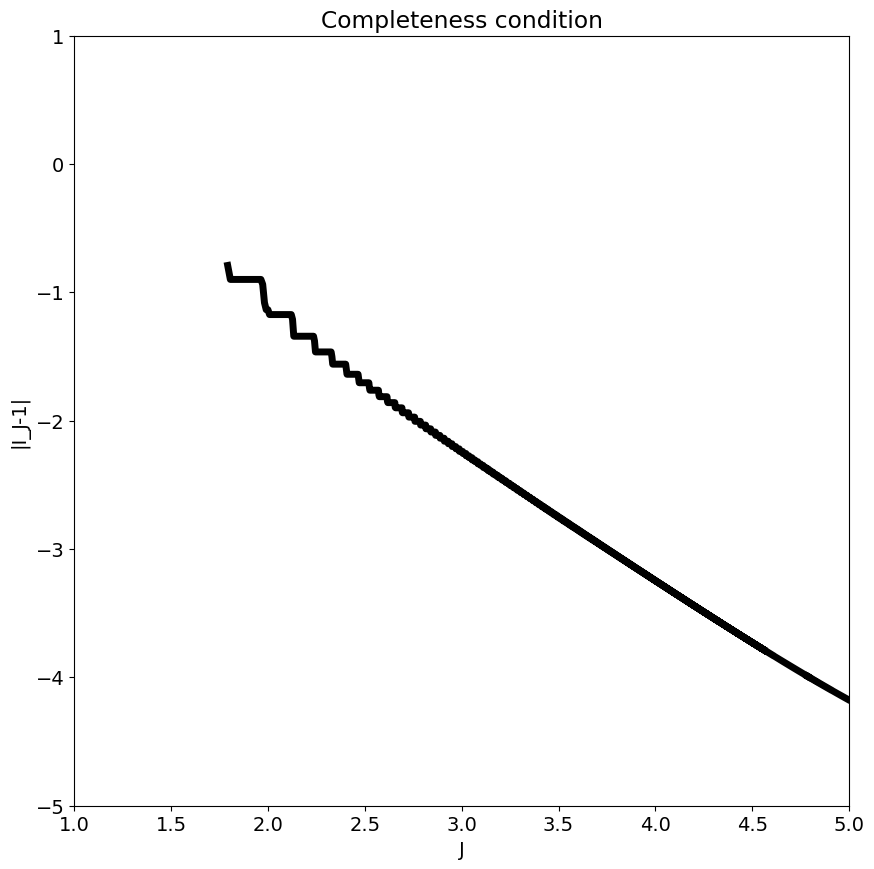

In [140]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(log10(num_qnms_v)[30:], log10(envelope)[30:], linewidth=5, color="black")
ax.set_xlim(1, 5);
ax.set_ylim(-5, 1);
ax.set_title("Completeness condition");
ax.set_xlabel("J")
ax.set_ylabel("|I_J-1|");